# Fukushima marine monitoring data: source exploration and assessment

> Exploration of the Japanese government's post-2011 marine monitoring compilation (biota, seabed sediment, seawater): what it holds, and what a MARIS handler must deal with.

**Work in progress, not yet reviewed.** The findings below are preliminary. The English translations of Japanese column names and values are drafts by an AI assistant, and the MARIS data team has not reviewed them yet. The comparison with the data already in MARIS is still to come.

The data are five Excel workbooks in `_data/fukushima_marine` (gitignored), received from a colleague. This notebook is an internal investigation ahead of a handler. It records the provider, time and spatial coverage, sample types, nuclides and columns, and the data problems a handler must solve. A comparison with what MARIS already holds will follow, once a current MARIS dump is available.

Columns and many values are in Japanese. Translations of distinct values go in lookup tables under `_data/fukushima_marine/lut/`, one CSV per field, with columns `ja`, `en`, `notes` and `reviewed`. Each value is translated once there, and reviewed before a handler uses it.

## Contents

- [Summary](#Summary): the data in brief, and the findings that affect a handler
- [Data and columns](#Data-and-columns): load the workbooks, profile and translate the columns
- [Lookup tables](#Lookup-tables): distinct values to translate, one CSV per field
- [Overview](#Overview): datasets, rows per year, analysed items, station map, Cs-137 over time
- [Sample identity and duplicates](#Sample-identity-and-duplicates): what identifies a sample, and what repeated rows are
- [Activity values](#Activity-values): text in numeric columns, detection limits
- [Next steps](#Next-steps)

## Summary

The workbooks hold the Japanese government's compilation of marine monitoring results after the 2011 Fukushima Daiichi accident. There are 743,128 result rows from March 2011 to October 2026, from six organisations: TEPCO, the Fisheries Agency (FA), the Ministry of the Environment (MOE), the Nuclear Regulation Authority (NRA), Fukushima Prefecture and the Ministry of Land, Infrastructure, Transport and Tourism (MLIT).

- Biota, 512,982 rows. The two FA files hold Cs-134 and Cs-137 for the same fishery products, from off Hokkaido to Tokyo Bay. They give only a production area, with no coordinates. TEPCO, MOE and FA results in `Marine_Biota.xlsx` (41,082 rows) have coordinates in 78% of rows, and include tritium, Sr-90, I-129 and C-14.
- Sediment, 48,443 rows, 23 analysed items, in Bq/kg dry weight. 99.9% of rows have coordinates.
- Seawater, 181,703 rows, 72 analysed items, in Bq/L. All rows have coordinates.

These findings affect a handler:

- No dataset has a sample ID or an uncertainty column.
- Repeated rows are separate samples or specimens, and a handler must keep them. For FA, the row position identifies a sample.
- About 31,850 FA rows are freshwater species.
- Many below-detection results have no detection limit. TEPCO seawater detection limits are often approximate (約, about) or ranges.
- The FA unit `Bq/kg` doesn't state whether it is wet or dry weight.

The Overview section has counts by year, organisation and analysed item, a station map, and Cs-137 over time. The highest biota values, up to 480,000 Bq/kg of Cs-137, are TEPCO fish from inside the Fukushima Daiichi port in 2012-2014. Each section with findings ends with a "FEEDBACK TO MARIS DATA TEAM" subsection, and Next steps lists the open work.

## Data and columns

In [ ]:
import pandas as pd, datetime as dt, re
from pathlib import Path
import matplotlib.pyplot as plt, numpy as np

### Load the workbooks

Each workbook has one data sheet, always the first. The biota workbooks also have a sheet describing the headers, and the Fisheries Agency ones a sheet that unifies species names.

In [ ]:
src = Path('../../_data/fukushima_marine')
fnames = {'biota': 'Marine_Biota.xlsx',
          'biota_fa_cs134': 'Marine_Biota_Fisheries_Agency_Cs134.xlsx',
          'biota_fa_cs137': 'Marine_Biota_Fisheries_Agency_Cs137.xlsx',
          'sediment': 'Marine_Sediment.xlsx',
          'seawater': 'Seawater.xlsx'}
dfs = {k: pd.read_excel(src/v, sheet_name=0) for k,v in fnames.items()}
{k: df.shape for k,df in dfs.items()}

{'biota': (41082, 20),
 'biota_fa_cs134': (235950, 20),
 'biota_fa_cs137': (235950, 20),
 'sediment': (48443, 19),
 'seawater': (181703, 19)}

### Profile the columns

`profile` gives one row per column: its type, non-null count, number of distinct values and a few examples. Columns with few distinct text values are categorical and get a lookup table.

In [ ]:
def profile(df, n_ex=3):
    "One row per column of `df`: dtype, non-null count, distinct count and example values"
    return pd.DataFrame({'dtype': df.dtypes.astype(str), 'non_null': df.notna().sum(), 'n_unique': df.nunique(),
                         'examples': [df[c].dropna().unique()[:n_ex].tolist() for c in df]})

In [ ]:
profile(dfs['biota'])

,dtype,non_null,n_unique,examples
A. 実施機関,str,41082,3,"[環境省, 東京電力, 水産庁]"
B. 対象海域,str,35534,3,"[近傍海域＋沿岸海域, 沿岸海域, 沿岸海域＋沖合海域＋外洋海域]"
B-1. 生産水域,str,41082,11,"[福島県沖, 三陸南部沖, 共同漁業権非設定区域内]"
B-2. 採取地点名,str,41079,206,"[久之浜沖, 勿来沖, 久之浜沿岸]"
B-3a. 緯度,float64,32165,126,"[37.265, 37.2677777777778, 37.40777778]"
B-3b. 経度,float64,32165,97,"[141.03944444, 141.071666666667, 141.15416667]"
C. 対象,str,39546,5,"[水生生物, 魚類, 頭足類]"
C-1. 農林水産物の区分,str,41082,4,"[その他水産動物類, 貝類, 魚類]"
C-2. 和名,str,41082,264,"[ツガルウニ, キヒトデ, マナマコ]"
C-3. 測定部位,str,40965,8,"[可食部, 全体, 貝殻]"


In [ ]:
profile(dfs['biota_fa_cs134'])

,dtype,non_null,n_unique,examples
A. 実施機関,str,235950,1,[水産庁]
B. 対象海域,str,231156,1,[沿岸海域＋沖合海域＋外洋海域]
B-1. 生産水域,str,204101,10,"[房総沖, 東京湾, その他海域]"
B-2. 採取地点名,str,13,4,"[新島村, 相模湾(藤沢沖), ｵﾎｰﾂｸ海]"
B-3a. 緯度,float64,0,0,[]
B-3b. 経度,float64,0,0,[]
C. 対象,str,230837,1,[水産物]
C-1. 農林水産物の区分,str,203878,5,"[魚類, その他水産動物類, 貝類]"
C-2. 和名,str,235950,638,"[キンメダイ, マサバ, ヤリイカ]"
C-3. 測定部位,str,203928,4,"[可食部, 加工品, 全体]"


In [ ]:
profile(dfs['sediment'])

,dtype,non_null,n_unique,examples
新ポイント名称,str,48406,204,"[T-11, T-14, M-G1]"
採取ポイント,str,48443,221,"[T-11, T-14, M-G1]"
⇐(別名),str,41830,173,"[岩沢海岸沖合3km, 小高区沖合3km, 四倉沖0.5km]"
分析項目,str,48443,23,"[Cs-134, Cs-137, Sr-90]"
緯度,float64,48416,145,"[37.24166667, 37.55277778, 37.083]"
経度,float64,48416,171,"[141.04722222, 141.0625, 141.257]"
採取日,datetime64[us],48443,4196,"[2011-04-29 00:00:00, 2011-05-09 00:00:00, 2011-05-10 00:00:00]"
採取時刻,object,13818,2011,"[08:30:00, 10:17:00, 13:27:00]"
検出 / 不検出,str,48443,2,"[=, <]"
放射能濃度(Bq/kg乾土),object,48443,2292,"[1200, 1300, 1400]"


In [ ]:
profile(dfs['seawater'])

,dtype,non_null,n_unique,examples
新ポイント名称,str,180199,465,"[T-2_OL, T-3_OL, T-4_OL]"
採取ポイント,str,181683,261,"[T-2(東京電力), T-3, T-4]"
⇐(別名),str,164422,214,"[1F 南放水口付近, 2F 北放水口付近, 2F 岩沢海岸付近]"
分析項目,str,181703,72,"[Cs-134, Cs-137, Pu-238]"
緯度,float64,181681,204,"[37.41583333, 37.32222222, 37.24166667]"
経度,float64,181681,193,"[141.03361111, 141.02638889, 141.01388889]"
採取日,datetime64[us],181703,14513,"[2011-03-21 00:00:00, 2011-03-22 00:00:00, 2011-03-23 00:00:00]"
採取時刻,object,111340,10189,"[14:30:00, 23:15:00, 23:45:00]"
検出 / 不検出,str,181703,2,"[=, <]"
放射能濃度(Bq/L),object,181703,1179,"[1500, 53, 48]"


### Translate the column names

Biota column names carry the codes A to F used by the header sheet. `col_en` translates the names and drops the codes, so a field shared by biota, sediment and seawater gets one English name.

In [ ]:
col_en = {
    'A. 実施機関': 'Implementing organisation', '実施機関': 'Implementing organisation',
    'B. 対象海域': 'Sea area',
    'B-1. 生産水域': 'Production area',
    'B-2. 採取地点名': 'Sampling point', '採取ポイント': 'Sampling point',
    '新ポイント名称': 'Station code',
    '⇐(別名)': 'Sampling point alias',
    'B-3a. 緯度': 'Latitude', '緯度': 'Latitude',
    'B-3b. 経度': 'Longitude', '経度': 'Longitude',
    'C. 対象': 'Target group',
    'C-1. 農林水産物の区分': 'Product category',
    'C-2. 和名': 'Japanese name',
    'C-3. 測定部位': 'Measured part',
    'D. 採取日': 'Sampling date', '採取日': 'Sampling date',
    '採取時刻': 'Sampling time',
    'D-1. 公表日': 'Publication date',
    'E-1. 分析項目': 'Analysed item', '分析項目': 'Analysed item',
    'E-2. 検出 / 不検出': 'Detected / not detected', '検出 / 不検出': 'Detected / not detected',
    'E-3. 放射能濃度': 'Activity concentration',
    '放射能濃度(Bq/kg乾土)': 'Activity concentration (Bq/kg dry soil)',
    '放射能濃度(Bq/L)': 'Activity concentration (Bq/L)',
    'E-4. 単位': 'Unit',
    '表層 / 中層 / 底層': 'Layer (surface / middle / bottom)',
    '採土深度(cm)': 'Sediment sampling depth (cm)',
    '採水深度(m)': 'Water sampling depth (m)',
    '水深(m)': 'Water depth (m)',
    '測定方法': 'Measurement method',
    'F. 備考': 'Remarks', '備考': 'Remarks',
    '地域': 'Region',
    '更新状況': 'Update status',
    '更新状況(対象海域)': 'Update status (sea area)',
    '更新状況(東電H-3地点別)': 'Update status (TEPCO H-3 by station)',
    '更新状況(採取ポイント)': 'Update status (sampling point)',
    '事業ID': 'Project ID'}
dfs = {k: df.rename(columns=col_en) for k,df in dfs.items()}
{k: [c for c in df if c not in col_en.values()] for k,df in dfs.items()}

{'biota': [],
 'biota_fa_cs134': [],
 'biota_fa_cs137': [],
 'sediment': [],
 'seawater': []}

Every column has a translation. Columns per dataset after renaming:

In [ ]:
pd.DataFrame({k: pd.Series(True, index=df.columns) for k,df in dfs.items()}).fillna(False)

,biota,biota_fa_cs134,biota_fa_cs137,sediment,seawater
Activity concentration,True,True,True,False,False
Activity concentration (Bq/L),False,False,False,False,True
Activity concentration (Bq/kg dry soil),False,False,False,True,False
Analysed item,True,True,True,True,True
Detected / not detected,True,True,True,True,True
Implementing organisation,True,True,True,True,True
Japanese name,True,True,True,False,False
Latitude,True,True,True,True,True
Layer (surface / middle / bottom),False,False,False,True,True
Longitude,True,True,True,True,True


The activity column has a different name in each dataset, because sediment and seawater put the unit in the name. `act` maps each dataset to its activity column.

In [ ]:
act = {k: 'Activity concentration' for k in ['biota', 'biota_fa_cs134', 'biota_fa_cs137']} | {
    'sediment': 'Activity concentration (Bq/kg dry soil)', 'seawater': 'Activity concentration (Bq/L)'}

## Lookup tables

`lut_fields` maps each lookup table to the columns whose values it translates. A table covers every dataset that has those columns, so a value shared by biota and seawater, such as an organisation or a nuclide, is translated once. Station codes and detection flags (`=`, `<`) need no translation and have no table.

In [ ]:
lut_fields = {
    'organisation': ['Implementing organisation'],
    'sea_area': ['Sea area'],
    'production_area': ['Production area'],
    'region': ['Region'],
    'sampling_point': ['Sampling point', 'Sampling point alias'],
    'target_group': ['Target group'],
    'product_category': ['Product category'],
    'species': ['Japanese name'],
    'measured_part': ['Measured part'],
    'nuclide': ['Analysed item'],
    'unit': ['Unit'],
    'layer': ['Layer (surface / middle / bottom)'],
    'method': ['Measurement method'],
    'remarks': ['Remarks'],
    'update_status': ['Update status', 'Update status (sea area)', 'Update status (TEPCO H-3 by station)']}

`distinct` counts the rows holding each value of the given columns, and lists the datasets it appears in.

In [ ]:
def distinct(dfs, cols):
    "Distinct values of `cols` across `dfs`, with row count `n` and the `datasets` they appear in"
    s = pd.concat([df[c].dropna().astype(str).str.strip().to_frame('ja').assign(dataset=k)
                   for k,df in dfs.items() for c in cols if c in df])
    return (s.groupby('ja').agg(n=('dataset', 'size'), datasets=('dataset', lambda x: ' '.join(sorted(set(x)))))
             .sort_values('n', ascending=False).reset_index())

In [ ]:
distinct(dfs, lut_fields['organisation'])

,ja,n,datasets
0,水産庁,473493,biota biota_fa_cs134 biota_fa_cs137
1,東京電力,159781,biota seawater sediment
2,福島県,55299,seawater sediment
3,環境省,30477,biota seawater sediment
4,原子力規制委員会,23853,seawater sediment
5,国土交通省,225,seawater


`update_lut` writes a table to `lut_path/<name>.csv`. It keeps the `en`, `notes` and `reviewed` entries already in the file, refreshes the counts, and adds new values with empty translations.

In [ ]:
lut_path = src/'lut'

def update_lut(name, cols):
    "Merge the distinct values of `cols` into the lookup CSV `name`, keeping existing translations"
    fn = lut_path/f'{name}.csv'
    new = distinct(dfs, cols)
    old = pd.read_csv(fn) if fn.exists() else pd.DataFrame(columns=['ja', 'en', 'notes', 'reviewed'])
    lut = new.merge(old[['ja', 'en', 'notes', 'reviewed']], on='ja', how='left')
    lut['reviewed'] = lut['reviewed'].fillna(False).astype(bool)
    lut.to_csv(fn, index=False)
    return lut

In [ ]:
lut_path.mkdir(exist_ok=True)
luts = {k: update_lut(k, v) for k,v in lut_fields.items()}
pd.Series({k: len(v) for k,v in luts.items()}, name='n_values')

organisation          6
sea_area              3
production_area      13
region               14
sampling_point      902
target_group          5
product_category      5
species             740
measured_part        10
nuclide              77
unit                  4
layer                15
method               18
remarks             452
update_status         2
Name: n_values, dtype: int64

### FEEDBACK TO MARIS DATA TEAM
Translations of the small tables are drafted and await review (`reviewed` is `False`). Points found while drafting:

- The Fisheries Agency unit is `Bq/kg` with no basis. The other biota unit is `Bq/kg 生重量` (wet weight). We need to confirm that the Fisheries Agency values are wet weight.
- `Bq/kg(加工)` values refer to processed products (7,762 rows). They may not belong in MARIS.
- Some values have variant spellings: 筋肉 and 筋⾁ (muscle, Kangxi radical), 魚類 and 魚 (fish), 福島県沖 and 福島沖 (off Fukushima), and the dashes － and -.
- The measurement method is `0` in 89 seawater rows.
- Some analysed items are not single nuclides: gross alpha, gross beta, and gamma-emitting nuclides. Results flagged 参考値 (reference value) are of lower reliability.
- The production area その他水域 and remarks such as 淡水 (fresh water) suggest that some Fisheries Agency rows are not marine.

## Overview

### Datasets at a glance

One row per dataset: sample type, implementing organisations, time span, number of analysed items, and the share of rows with coordinates and below detection. `org_short` gives each organisation's abbreviation from the lookup table, or its English name when it has none.

In [ ]:
sample_type = {'biota': 'Biota', 'biota_fa_cs134': 'Biota', 'biota_fa_cs137': 'Biota', 'sediment': 'Sediment', 'seawater': 'Seawater'}
org_en = luts['organisation'].set_index('ja')['en']
org_short = org_en.str.extract(r'\((\w+)\)$')[0].fillna(org_en)

def overview(k):
    "Summary of dataset `k`"
    df = dfs[k]
    return {'sample type': sample_type[k],
            'organisations': ', '.join(sorted(df['Implementing organisation'].dropna().map(org_short).unique())),
            'rows': len(df), 'first': df['Sampling date'].min().date(), 'last': df['Sampling date'].max().date(),
            'analysed items': df['Analysed item'].nunique(),
            'with coordinates (%)': round(100 * df['Latitude'].notna().mean(), 1),
            'below detection (%)': round(100 * df['Detected / not detected'].eq('<').mean(), 1)}

pd.DataFrame({k: overview(k) for k in dfs})

,biota,biota_fa_cs134,biota_fa_cs137,sediment,seawater
sample type,Biota,Biota,Biota,Sediment,Seawater
organisations,"FA, MOE, TEPCO",FA,FA,"Fukushima Prefecture, MOE, NRA, TEPCO","Fukushima Prefecture, MLIT, MOE, NRA, TEPCO"
rows,41082,235950,235950,48443,181703
first,2012-01-13,2011-03-24,2011-03-24,2011-04-29,2011-03-21
last,2026-09-29,2026-09-01,2026-09-01,2026-08-28,2026-10-05
analysed items,10,1,1,23,72
with coordinates (%),78.3,0.0,0.0,99.9,100.0
below detection (%),68.5,92.0,84.8,37.1,67.0


`allrows` stacks the context of every dataset, for counts across datasets. The two Fisheries Agency files hold the same samples, so counts by sample use `samples`, which leaves out the Cs-137 file.

In [ ]:
allrows = pd.concat([df[['Implementing organisation', 'Sampling date', 'Analysed item']].assign(dataset=k, sample_type=sample_type[k])
                     for k,df in dfs.items()], ignore_index=True)
allrows['organisation'] = allrows['Implementing organisation'].map(org_short)
allrows['year'] = allrows['Sampling date'].dt.year.astype('Int64')
samples = allrows[allrows.dataset.ne('biota_fa_cs137')]

### Rows per year

Rows per year, by sample type and organisation. Monitoring starts in March 2011 and continues into 2026.

In [ ]:
pd.crosstab(samples['year'], [samples['sample_type'], samples['organisation']], margins=True)

sample_type    Biota                          Seawater                                        Sediment                        All
organisation      FA   MOE  TEPCO Fukushima Prefecture MLIT    MOE    NRA   TEPCO Fukushima Prefecture   MOE   NRA  TEPCO        
year                                                                                                                             
2011            5201     0      0                  944    0    140      0    5965                  411   167   350    180   13358
2012           18443   418   2090                 1314    0    748     18    5831                 1092   618   318    953   31843
2013           20554   280   3833                 2382    0   1150    864    6151                 1500   738   416    922   38790
2014           20788   319   2794                 3081    0   1068   1370    6994                 1674   694   451    924   40157
2015           19194   284   2525                 2991    0   1068   1366    6796                 1690   615   447    916   37892
2016           18352   230   2516                 2983    0   1068   1366    6598                 1689   606   447    916   36771
2017           17368   241   2808                 2477    0   1068   1366    6640                 1383   606   447    920   35324
2018           14474   203   2646                 2147    0   1068   1366    6692                 1310   603   447    900   31856
2019           13454   141   2520                 2069    0   1068   1366    6719                 1286   572   447    914   30556
2020           11095   147   2049                 2069    0    840   1348    6692                 1326   458   450    900   27374
2021           12945   136   1958                 2069    0   1068   1362    6595                 1318   572   451    890   29364
2022           13524   184   2539                 2231    0   1740   1299    7042                 1318   570   449    853   31749
2023           14421   318   2608                 2573  114   2048   1274    8453                 1322   570   449    898   35048
2024           15853   284   1950                 2497   57   2054   1274    8626                  970   570   449    894   35478
2025           14412   205   2068                 2328   27   1642   1274    8712                  882   564   449    906   33469
2026            7463    39   1156                 1427   27    577    327    5735                  546   110   146    594   18147
All           237541  3429  36060                35582  225  18415  17240  110241                19717  8633  6613  13480  507176

### Analysed items

Rows per analysed item and sample type, for items with at least 1,000 rows:

In [ ]:
nuc = pd.crosstab(allrows['Analysed item'], allrows['sample_type'], margins=True)
nuc[nuc['All'] >= 1000].sort_values('All', ascending=False)

sample_type,Biota,Seawater,Sediment,All
Analysed item,,,,
All,504142,181703,48443,734288
Cs-134,249839,62236,19506,331581
Cs-137,249839,62231,19498,331568
H-3,0,15454,0,15454
全β,0,14299,0,14299
H-3(迅速分析),0,6005,0,6005
Sr-90,522,3933,1240,5695
I-131,59,232,2524,2815
Pu-238,0,1457,492,1949


### Station map

`stations` holds each distinct position, with its organisation and sample type. The Fisheries Agency caesium files have no coordinates, so they are absent. The map has two panels: the full extent, which reaches the open Pacific for some biota, and the coast near Fukushima Daiichi (1F).

In [ ]:
stations = pd.concat([dfs[k][['Implementing organisation', 'Latitude', 'Longitude']].dropna().drop_duplicates()
                      .assign(sample_type=sample_type[k]) for k in ['biota', 'sediment', 'seawater']])
stations['organisation'] = stations['Implementing organisation'].map(org_short)
stations.groupby(['sample_type', 'organisation']).size().unstack(fill_value=0)

organisation,FA,Fukushima Prefecture,MLIT,MOE,NRA,TEPCO
sample_type,,,,,,
Biota,140,0,0,5,0,12
Seawater,0,67,1,84,58,55
Sediment,0,53,0,61,51,45


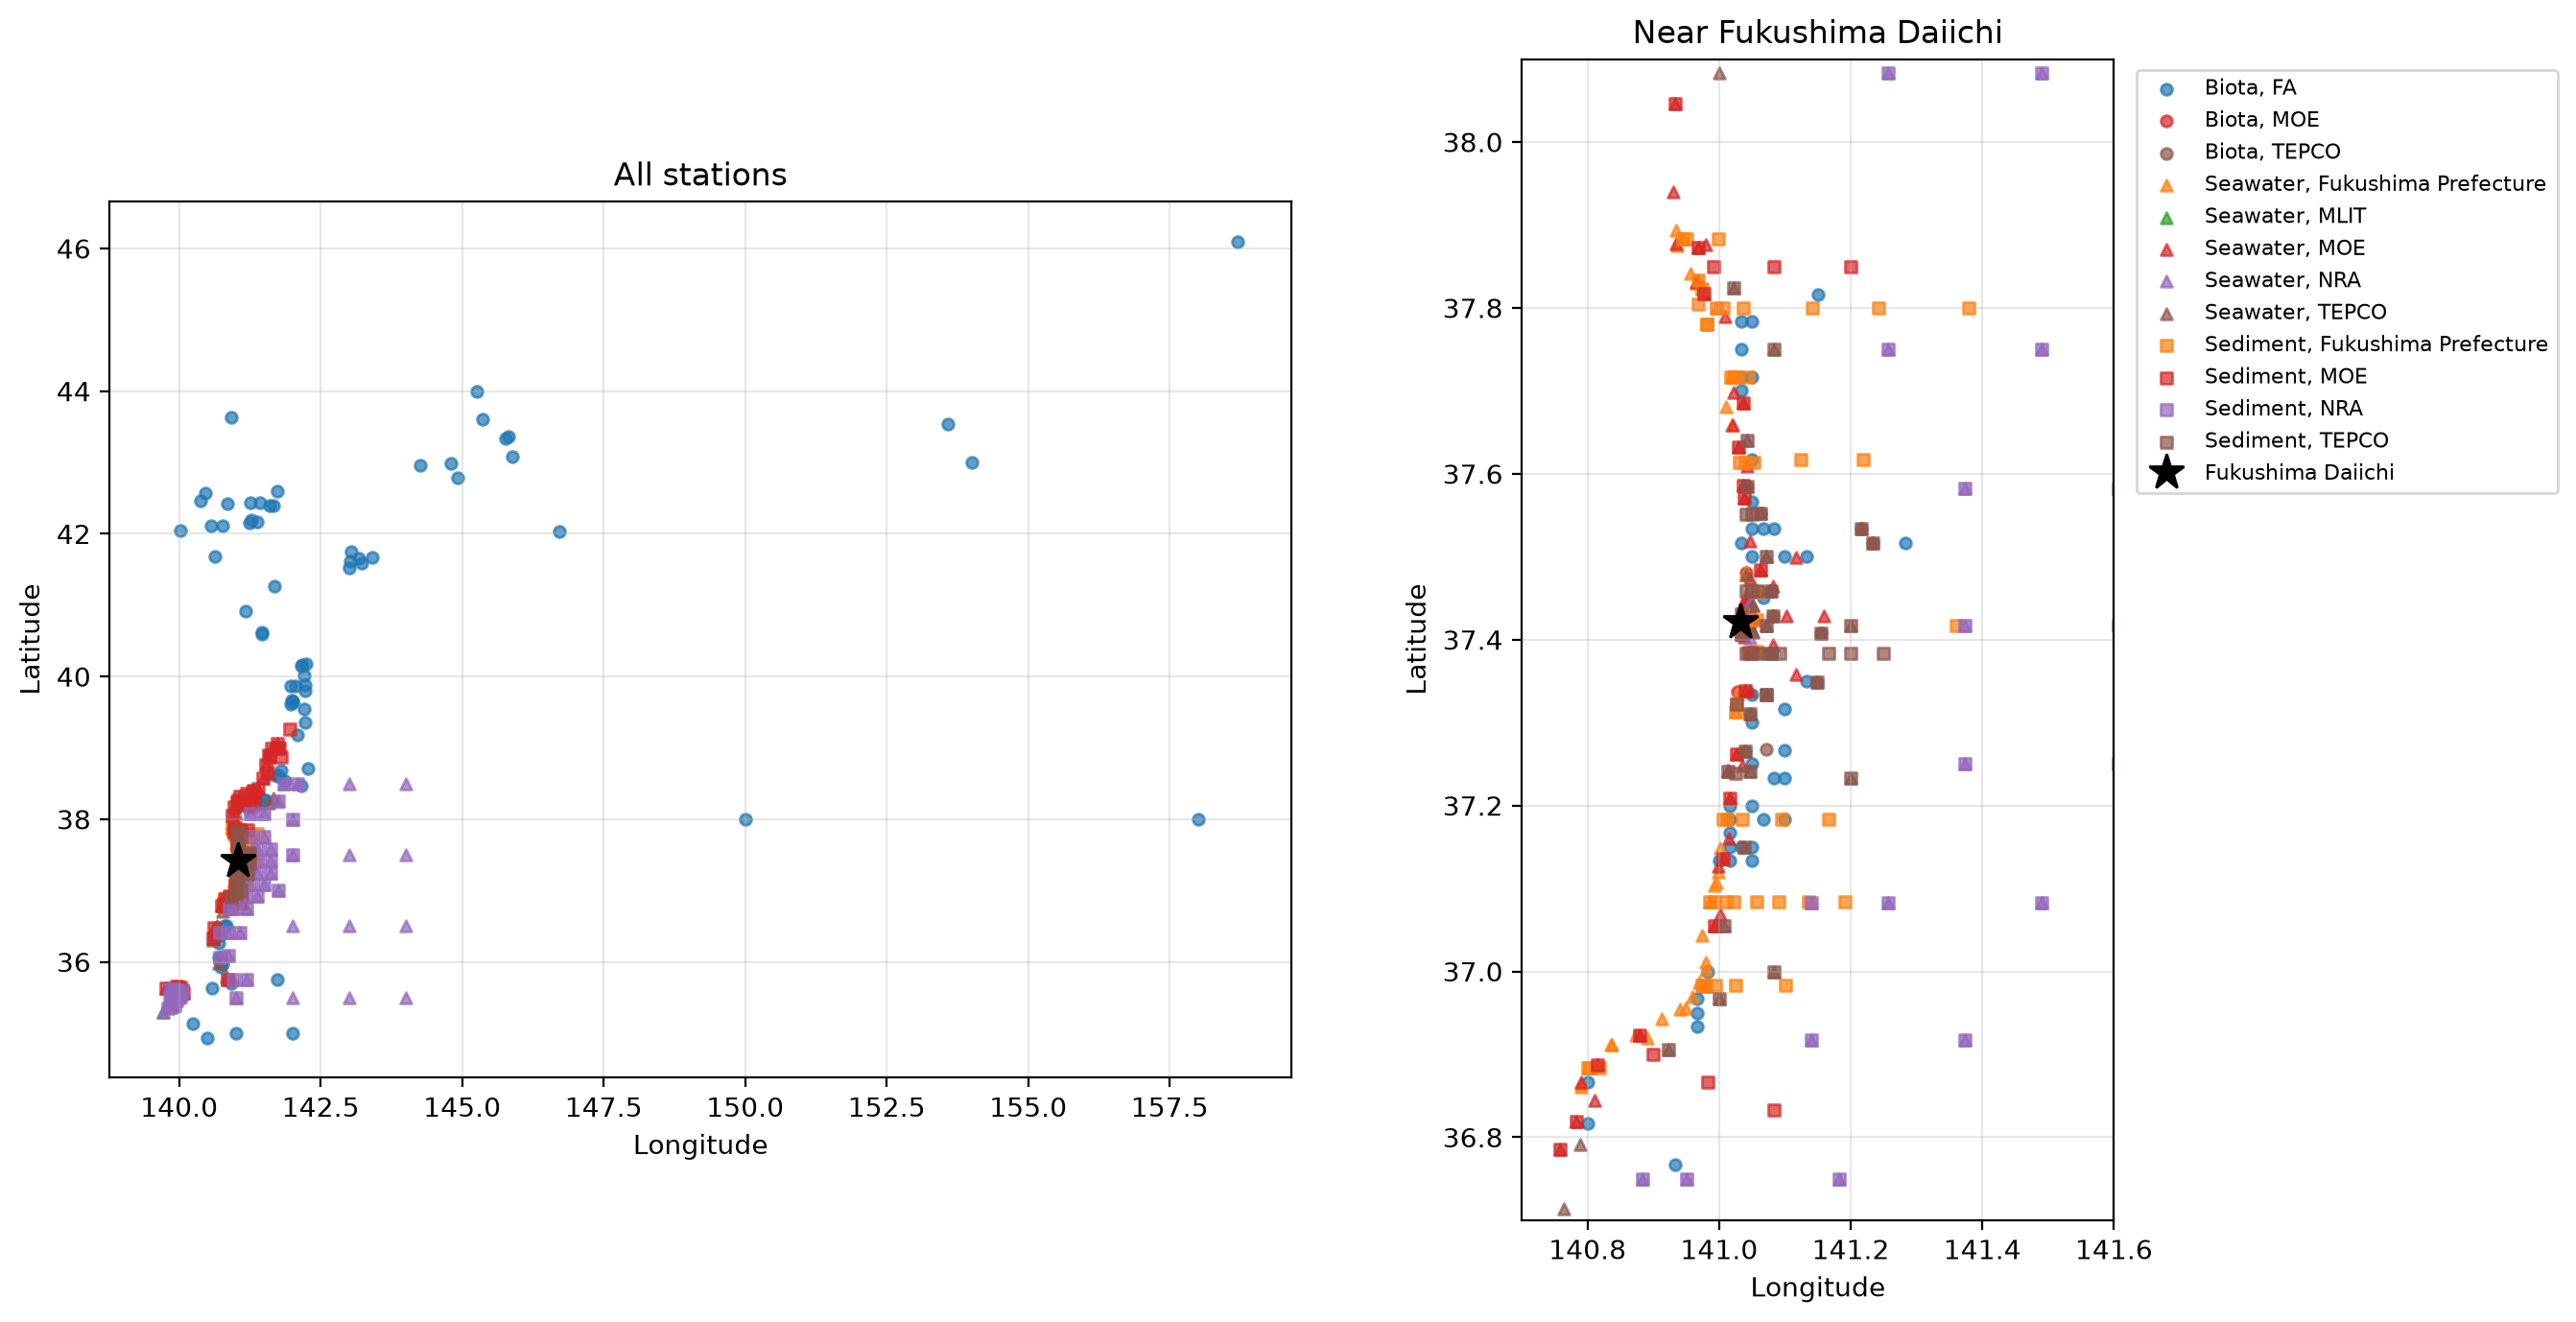

In [ ]:
f1 = (141.0325, 37.4214)
markers = {'Biota': 'o', 'Sediment': 's', 'Seawater': '^'}
colours = dict(zip(sorted(stations['organisation'].unique()), plt.cm.tab10.colors))

def plot_stations(ax, extent=None):
    "Scatter `stations` on `ax` by organisation (colour) and sample type (marker), limited to `extent` (lon0, lon1, lat0, lat1)"
    for (st, org), g in stations.groupby(['sample_type', 'organisation']):
        ax.scatter(g['Longitude'], g['Latitude'], marker=markers[st], color=colours[org], s=18, alpha=0.7, label=f'{st}, {org}')
    ax.plot(*f1, marker='*', ms=14, color='k', ls='', label='Fukushima Daiichi')
    if extent: ax.set_xlim(extent[:2]); ax.set_ylim(extent[2:])
    ax.set_aspect(1 / np.cos(np.radians(37.5)))
    ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.grid(alpha=0.3)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
plot_stations(ax1); ax1.set_title('All stations')
plot_stations(ax2, (140.7, 141.6, 36.7, 38.1)); ax2.set_title('Near Fukushima Daiichi')
ax2.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8)
plt.tight_layout()

### Cs-137 over time

Cs-137 over time, by sample type. Biota leaves out freshwater rows and processed products. Its unit mixes `Bq/kg 生重量` (wet weight) with the Fisheries Agency's `Bq/kg`, whose basis is not stated. `cs137` keeps rows with a positive numeric value.

In [ ]:
def cs137(k):
    "Cs-137 rows of dataset `k` with a positive numeric value: date, value, detection flag, sample type"
    df = dfs[k]; v = pd.to_numeric(df[act[k]], errors='coerce')
    keep = df['Analysed item'].eq('Cs-137') & v.gt(0)
    if 'Unit' in df: keep &= ~df['Remarks'].eq('淡水') & df['Unit'].isin(['Bq/kg', 'Bq/kg 生重量'])
    return pd.DataFrame({'date': df['Sampling date'], 'value': v, 'flag': df['Detected / not detected'],
                         'sample_type': sample_type[k]})[keep]

cs = pd.concat([cs137(k) for k in dfs], ignore_index=True)
pd.crosstab(cs['sample_type'], cs['flag'])

flag,<,=
sample_type,,
Biota,182970,27983
Seawater,24479,29981
Sediment,344,18929


`monthly` summarises `cs137` by sample type and month. A below-detection result counts at its detection limit, which is an upper bound on the true value. The 10th, 50th and 90th percentiles then describe all results, not only the detected ones. Once more than half the results in a month are below detection, the median is a detection limit, and it follows the median detection limit. The table also gives the share of results below detection.

In [ ]:
cs['month'] = cs['date'].dt.to_period('M').dt.to_timestamp()
g = cs.groupby(['sample_type', 'month'])
monthly = pd.concat({'p10': g['value'].quantile(0.1), 'median': g['value'].median(), 'p90': g['value'].quantile(0.9),
                     'median DL': cs[cs['flag'].eq('<')].groupby(['sample_type', 'month'])['value'].median(),
                     'below DL (%)': g['flag'].apply(lambda s: 100 * s.eq('<').mean())}, axis=1)
monthly.groupby('sample_type').head(2)

p10  median       p90  median DL  below DL (%)
sample_type month                                                         
Biota       2012-01-01     4.12    33.0     94.00        NaN           0.0
            2012-02-01     1.34     1.9      9.18        NaN           0.0
Seawater    2011-03-01    35.20   595.0  19200.00        NaN           0.0
            2011-04-01    44.90   245.0   5400.00        NaN           0.0
Sediment    2011-04-01  1220.00  1300.0   1380.00        NaN           0.0
            2011-05-01     7.10    62.0   1437.00        NaN           0.0

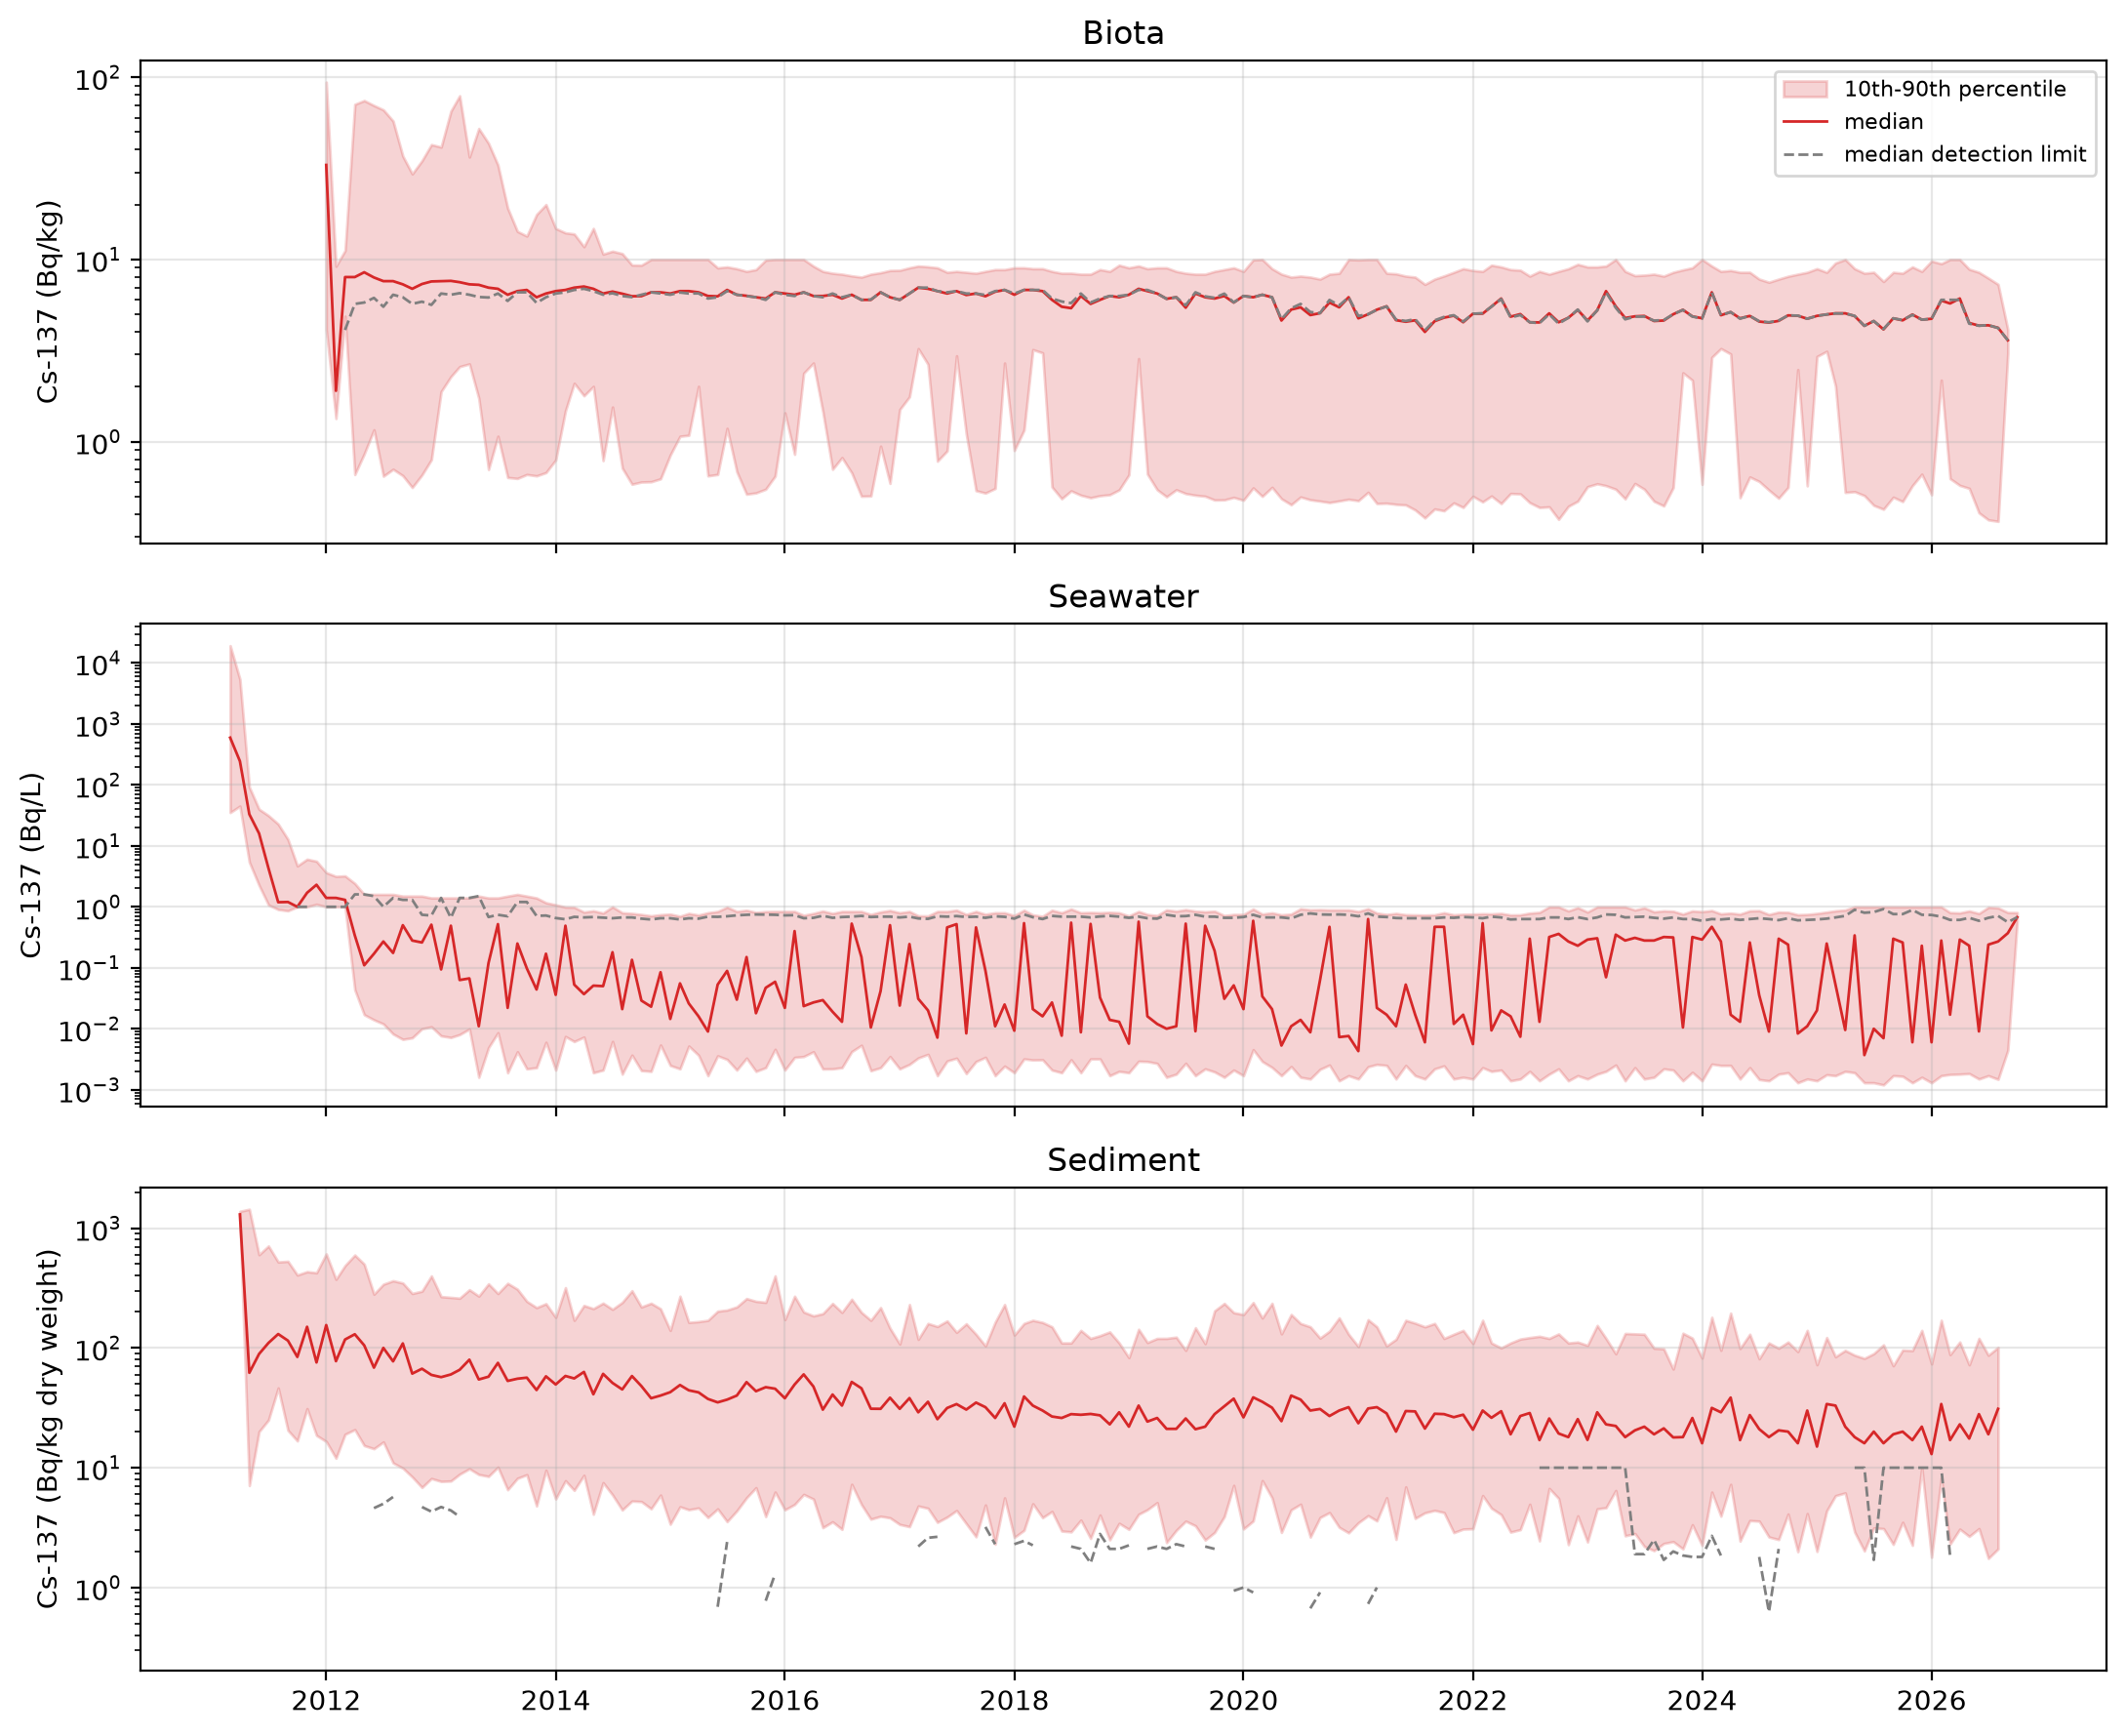

In [ ]:
units = {'Biota': 'Bq/kg', 'Sediment': 'Bq/kg dry weight', 'Seawater': 'Bq/L'}
fig, axs = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ax, (st, x) in zip(axs, monthly.groupby('sample_type')):
    x = x.droplevel('sample_type')
    ax.fill_between(x.index, x['p10'], x['p90'], color='tab:red', alpha=0.2, label='10th-90th percentile')
    ax.plot(x.index, x['median'], color='tab:red', lw=1, label='median')
    ax.plot(x.index, x['median DL'], color='tab:grey', lw=1, ls='--', label='median detection limit')
    ax.set_yscale('log'); ax.set_ylabel(f'Cs-137 ({units[st]})'); ax.set_title(st); ax.grid(alpha=0.3)
axs[0].legend(fontsize=8)
plt.tight_layout()

From 2016, the biota median equals the median detection limit: more than 90% of biota results are below detection. In seawater, the median falls to about 0.02-0.1 Bq/L, while the 90th percentile stays near 1 Bq/L. That upper part of the band is made of detection limits, mostly of the order of 1 Bq/L, not of high concentrations. Sediment results are almost all detected, and the band shows a steady decline.

## Sample identity and duplicates

No dataset has a sample ID. This section looks for the columns that identify a sample, and for rows that repeat a measurement.

### Fisheries Agency files: one sample per row

The two Fisheries Agency files have the same row count. `meas` holds the columns that describe a measurement. If the files align row by row, every other column is equal in both.

In [ ]:
meas = ['Analysed item', 'Detected / not detected', 'Activity concentration']
fa134, fa137 = dfs['biota_fa_cs134'], dfs['biota_fa_cs137']
ctx = [c for c in fa134 if c not in meas]
diff = fa134[ctx].ne(fa137[ctx]) & ~(fa134[ctx].isna() & fa137[ctx].isna())
diff.sum()

Implementing organisation         0
Sea area                          0
Production area                   1
Sampling point                    0
Latitude                          0
Longitude                         0
Target group                      0
Product category                  0
Japanese name                     0
Measured part                     0
Sampling date                     0
Publication date                  0
Unit                              0
Remarks                           1
Update status (sea area)          0
Update status (sampling point)    0
Project ID                        0
dtype: int64

Two rows differ. In row 197102 the same アイナメ (fat greenling) sample is off Fukushima in one file and off Boso in the other. In row 215127 only the deleted value quoted in the remark differs. Apart from these, the row position identifies a Fisheries Agency sample, and the two files join on it.

In [ ]:
fa134.loc[diff.any(axis=1), ['Production area', 'Remarks', 'Japanese name', 'Sampling date']].join(
    fa137[['Production area', 'Remarks']], rsuffix=' (Cs-137 file)')

,Production area,Remarks,Japanese name,Sampling date,Production area (Cs-137 file),Remarks (Cs-137 file)
197102,福島県沖,NaN,アイナメ,2023-11-09,房総沖,NaN
215127,北海道・青森県沖太平洋,25/07/16分析手順に誤りがあったため削除(旧：<0.226),マナマコ,2025-01-20,北海道・青森県沖太平洋,25/07/16分析手順に誤りがあったため削除(旧：<0.246)


### Freshwater species

The remark 淡水 (fresh water) marks freshwater species, such as イワナ (char), ヤマメ (masu salmon) and アユ (ayu). Only 16 of these rows have a production area, and 4,418 have no measurement. One other row has no analysed item.

In [ ]:
fw = fa134['Remarks'].eq('淡水')
pd.Series({'freshwater rows': fw.sum(), 'with a value': fa134.loc[fw, 'Activity concentration'].notna().sum(),
           'with a production area': fa134.loc[fw, 'Production area'].notna().sum(),
           'no analysed item, not freshwater': (fa134['Analysed item'].isna() & ~fw).sum()})

freshwater rows                     31854
with a value                        26219
with a production area                 16
no analysed item, not freshwater        1
dtype: int64

### Fisheries Agency tritium in `Marine_Biota.xlsx`

`Marine_Biota.xlsx` also holds Fisheries Agency rows. They are all tritium, sampled from June 2022, so they don't overlap with the caesium files.

In [ ]:
b = dfs['biota']
b[b['Implementing organisation'].eq('水産庁')].agg({'Analysed item': 'unique', 'Sampling date': ['min', 'max']})

,Analysed item,Sampling date
unique,"[H-3(組織自由水型), H-3(全トリチウム), nan]",NaT
min,NaN,2022-06-20
max,NaN,2026-09-29


### Duplicate rows

Exact duplicate rows are common in the Fisheries Agency files. Most are below-detection results with the same detection limit, such as 32 ワカメ (wakame) samples from off northern Sanriku on 2013-04-15, all `< 20`. The compilation has no landing port or municipality to tell them apart, so they are separate samples, not copies.

In [ ]:
{k: df.duplicated().sum() for k,df in dfs.items()}

{'biota': np.int64(144),
 'biota_fa_cs134': np.int64(21061),
 'biota_fa_cs137': np.int64(20340),
 'sediment': np.int64(4),
 'seawater': np.int64(0)}

In TEPCO biota, the repeated rows are several specimens of one species from one station on one day:

In [ ]:
b[b.duplicated(keep=False)].head(4)[['Sampling point', 'Japanese name', 'Sampling date', 'Analysed item', 'Activity concentration']]

,Sampling point,Japanese name,Sampling date,Analysed item,Activity concentration
1347,T-S1,アイナメ,2012-08-29,Cs-134,56.0
1348,T-S1,アイナメ,2012-08-29,Cs-134,56.0
1351,T-S1,アイナメ,2012-08-29,Cs-134,29.0
1352,T-S1,アイナメ,2012-08-29,Cs-134,29.0


### Candidate sample keys

`keys` lists candidate sample keys: the columns that together identify a sample. `key_stats` counts the samples each key gives, and the rows where one sample has two results for the same nuclide. Those rows are either several specimens or repeat analyses.

In [ ]:
bkey = ['Implementing organisation', 'Production area', 'Sampling point', 'Latitude', 'Longitude',
        'Japanese name', 'Measured part', 'Sampling date', 'Remarks']
wkey = ['Implementing organisation', 'Station code', 'Sampling point', 'Latitude', 'Longitude',
        'Sampling date', 'Sampling time', 'Layer (surface / middle / bottom)']
keys = {'biota': bkey, 'sediment': wkey + ['Sediment sampling depth (cm)'], 'seawater': wkey + ['Water sampling depth (m)']}

In [ ]:
def key_stats(df, key):
    "Samples given by `key` in `df`, and rows repeating a nuclide within a sample"
    ng = df.groupby(key, dropna=False, sort=False).ngroups
    rep = df.duplicated(key + ['Analysed item'], keep=False)
    return {'rows': len(df), 'samples': ng, 'meas_per_sample': round(len(df)/ng, 2), 'rows_repeating_nuclide': rep.sum()}

pd.DataFrame({k: key_stats(dfs[k], v) for k,v in keys.items()})

,biota,sediment,seawater
rows,41082.00,48443.0,181703.00
samples,19148.00,19416.0,67522.00
meas_per_sample,2.15,2.5,2.69
rows_repeating_nuclide,5971.00,512.0,454.00


Repeats by organisation and analysed item. In biota they are mostly TEPCO caesium specimens and tritium. In seawater and sediment they are few.

In [ ]:
def repeats(k):
    "Rows of dataset `k` repeating a nuclide within a sample, by organisation and analysed item"
    df = dfs[k]
    return df[df.duplicated(keys[k] + ['Analysed item'], keep=False)].groupby(['Implementing organisation', 'Analysed item']).size()

pd.concat({k: repeats(k) for k in keys}, axis=1).fillna(0).astype(int).sort_values('biota', ascending=False)

biota  sediment  seawater
Implementing organisation Analysed item                           
東京電力                      Cs-134          1706       202       120
                          Cs-137          1706       202       118
                          H-3(組織自由水型)      764         0         0
                          H-3(有機結合型)       752         0         0
水産庁                       H-3(組織自由水型)      541         0         0
環境省                       H-3(組織自由水型)      234         0         0
                          H-3(有機結合型)       234         0         0
水産庁                       H-3(全トリチウム)       24         0         0
東京電力                      Sr-90              6         0         2
環境省                       Cs-134             2        22         0
                          Cs-137             2        24         0
原子力規制委員会                  Sr-90              0        48         0
福島県                       Cs-134             0         6        44
                          Cs-137             0         4        44
                          K-40               0         4         0
東京電力                      全β                 0         0         6
福島県                       H-3                0         0       108
                          全β(参考値)            0         0        12

### Sampling time

The sampling time mixes `time` values with full `datetime` values. The date part of a `datetime` equals the sampling date in every sediment row and in all but 8 seawater rows.

In [ ]:
def time_types(df):
    "Count of sampling-time types, and of `datetime` values whose date differs from the sampling date"
    t = df['Sampling time']; is_dt = t.map(lambda o: isinstance(o, dt.datetime))
    return {'time': t.map(lambda o: isinstance(o, dt.time)).sum(), 'datetime': is_dt.sum(),
            'datetime, other date': (t[is_dt].map(lambda o: o.date()) != df.loc[is_dt, 'Sampling date'].dt.date).sum()}

pd.DataFrame({k: time_types(dfs[k]) for k in ['sediment', 'seawater']})

,sediment,seawater
time,10772,81707
datetime,3046,29633
"datetime, other date",0,8


### FEEDBACK TO MARIS DATA TEAM
- No dataset has a sample ID. For the Fisheries Agency, the row position is the sample identity, and the Cs-134 and Cs-137 files join on it. In row 197102 the two files disagree on the production area (off Fukushima or off Boso).
- About 31,850 Fisheries Agency rows (13.5%) are freshwater species, marked 淡水 in the remarks. They are out of scope for marine data. 4,418 of them have no measurement.
- Exact duplicate rows are separate samples or specimens, not copies: about 21,000 in each Fisheries Agency file and 144 in TEPCO biota. Dropping them would lose data.
- Candidate sample keys give about 19,100 biota, 19,400 sediment and 67,500 seawater samples. Within a sample, a nuclide repeats in 5,971 biota rows, 512 sediment rows and 454 seawater rows. These are several specimens or repeat analyses. The handler needs a rule for each case.
- The Fisheries Agency rows in `Marine_Biota.xlsx` are tritium from June 2022, separate from the caesium files.
- The sampling time mixes times and full timestamps. In 8 seawater rows the timestamp's date differs from the sampling date.

## Activity values

### Text in numeric columns

In sediment and seawater, the activity column has type `object`, so it holds text as well as numbers. `non_numeric` lists the distinct entries of a column that are not numbers.

In [ ]:
def non_numeric(s):
    "Distinct non-null entries of `s` that `pd.to_numeric` can't parse, with counts"
    s = s.dropna()
    return s[pd.to_numeric(s, errors='coerce').isna()].astype(str).value_counts()

In [ ]:
non_numeric(dfs['seawater'][act['seawater']])

Activity concentration (Bq/L)
不検出          10631
ND            1610
約1.1E+00       570
約6.0E+00       461
約9.0E+00       461
             ...  
約7.8E-01         1
約1.2             1
約0.87～2.5        1
約0.81～2.1        1
08:24:00         1
Name: count, Length: 150, dtype: int64

In [ ]:
non_numeric(dfs['sediment'][act['sediment']])

Activity concentration (Bq/kg dry soil)
不検出         4414
ND           762
検出限界値未満       28
約8.0E-01      17
約9.0E-03       2
Name: count, dtype: int64

In [ ]:
non_numeric(dfs['seawater']['Water sampling depth (m)'])

Water sampling depth (m)
0.5m         90
全水深から1m上層    90
0-1          22
Name: count, dtype: int64

The water sampling depth has three text forms: `0.5m`, `0-1` (a range) and 全水深から1m上層, which reads as 1 m above the seabed.

### Entry kinds and the detection flag

The text entries follow a few patterns. `val_kind` sorts each activity entry into one of them:

- `not detected (text)`: 不検出 (not detected), `ND` or 検出限界値未満 (below the detection limit), with no value
- `approx number`: 約 (about) followed by a number, such as `約1.1E+00`
- `approx other`: 約 followed by a range, such as `約16～28` or `約1.3E+00<&<約1.4E+00`
- `other text`: anything else

In [ ]:
def val_kind(o):
    "Kind of activity entry `o`: missing, number, not detected (text), approx number, approx other or other text"
    if pd.isna(o): return 'missing'
    if isinstance(o, (int, float)): return 'number'
    s = str(o).strip()
    if s in ('不検出', 'ND', '検出限界値未満'): return 'not detected (text)'
    if re.fullmatch(r'約[\d.Ee+-]+', s): return 'approx number'
    return 'approx other' if s.startswith('約') else 'other text'

Crossing the kind with the detection flag shows what `<` means. Every text and approximate entry carries `<`. So 約 marks an approximate detection limit, not an approximate result, and a number with `<` is the detection limit. A `<` without a number (text or missing) has no detection limit. The Fisheries Agency files have about 9,000 such rows each, and the freshwater rows without a measurement have no flag at all.

In [ ]:
def flag_kinds(k):
    "Rows of dataset `k` by activity-entry kind and detection flag"
    df = dfs[k]
    return pd.crosstab(df[act[k]].map(val_kind), df['Detected / not detected'].fillna('missing'))

pd.concat({k: flag_kinds(k) for k in act}).fillna(0).astype(int)

Detected / not detected                  <      =  missing
biota          number                28138  12944        0
biota_fa_cs134 missing                8977      0     4420
               number               208104  14449        0
biota_fa_cs137 missing                8976      0     4420
               number               191055  31499        0
sediment       approx number            19      0        0
               not detected (text)    5204      0        0
               number                12734  30486        0
seawater       approx number          5852      0        0
               approx other            254      0        0
               not detected (text)   12241      0        0
               number               103461  59894        0
               other text                1      0        0

### Approximate detection limits

In seawater, all 6,106 approximate detection limits are TEPCO results, mostly caesium and gross beta. Sediment has 19 more.

In [ ]:
sw = dfs['seawater']; sw_kind = sw[act['seawater']].map(val_kind)
sw[sw_kind.str.startswith('approx')].groupby(['Implementing organisation', 'Analysed item']).size().sort_values(ascending=False)

Implementing organisation  Analysed item
東京電力                       Cs-134           2998
                           Cs-137           2801
                           全β                257
                           H-3                26
                           Sr-90              12
                           Pu-238              6
                           Pu-239+240          6
dtype: int64

The ranges are detection-limit ranges. The one `other text` entry is a time, 08:24, in the activity column.

In [ ]:
sw.loc[sw_kind.isin(['approx other', 'other text']), act['seawater']].astype(str).value_counts()

Activity concentration (Bq/L)
約16～28                 202
約16～27                  14
約1.3E+00<&<約1.4E+00     10
約4.0E+00<&<約1.4E+01      9
約1.4E+01<&<約1.5E+01      8
約4.0E+00<&<約1.5E+01      5
約5.0E+00<&<約1.6E+01      4
約0.87～2.5                1
約0.81～2.1                1
08:24:00                 1
Name: count, dtype: int64

### Zero detection limits

No value is negative. Five are zero, all with `<`: a detection limit of 0 is invalid.

In [ ]:
pd.concat({k: dfs[k].loc[pd.to_numeric(dfs[k][act[k]], errors='coerce') <= 0,
                          ['Implementing organisation', 'Analysed item', 'Detected / not detected', act[k], 'Sampling date']]
           for k in act})

Implementing organisation Analysed item Detected / not detected  Activity concentration Sampling date Activity concentration (Bq/kg dry soil) Activity concentration (Bq/L)
biota_fa_cs134 190489                       水産庁        Cs-134                       <                     0.0    2023-05-25                                     NaN                           NaN
               190490                       水産庁        Cs-134                       <                     0.0    2023-05-25                                     NaN                           NaN
               190491                       水産庁        Cs-134                       <                     0.0    2023-05-25                                     NaN                           NaN
seawater       73263                   原子力規制委員会        Cs-134                       <                     NaN    2017-12-06                                     NaN                             0
               73330                   原子力規制委員会        Cs-134                       <                     NaN    2017-12-07                                     NaN                             0

### FEEDBACK TO MARIS DATA TEAM
- No dataset has an uncertainty column.
- `<` with a number gives the detection limit.
- `<` without a detection limit occurs in 8,977 rows of each Fisheries Agency file, 5,204 sediment rows and 12,241 seawater rows. The value is missing, or is text such as 不検出 or `ND`. MARIS needs a rule for below-detection results with an unknown detection limit.
- 6,125 detection limits are approximate (約, about), and 254 are ranges such as `約16～28`. In seawater they are all TEPCO results. The 19 in sediment are NRA results.
- Five detection limits are 0: three Fisheries Agency Cs-134 rows from 2023-05-25 and two NRA seawater Cs-134 rows from December 2017.
- One seawater activity cell holds a time (08:24).
- The water sampling depth is text in 202 rows. The form 全水深から1m上層 (1 m above the seabed) needs the water depth to become a number.

## Next steps

- Review the draft translations in the lookup tables. Translate the sampling points (902 values) and remarks (452 values). Species names (740 values) are left for the handler, which matches them to the MARIS species list.
- Explore coordinates: coverage per organisation, recovering missing coordinates from station codes or names, stations that moved, and positions that look wrong.
- Compare with MARIS, starting from a current dump of the TEPCO data in MARIS.
- Refine the charts.